# 04 -- Template calibration: get a MUSE cube, bin it, and pick a representative template subset

**Run this notebook first for any real MUSE target**, before
`05_noise_correlation.ipynb`/`07_full_galaxy_analysis.ipynb`. It answers
one question a hand-picked template recipe (the approach every earlier
notebook in this series uses) can't: *out of the full E-MILES grid, which
stellar populations does this specific target's spectra actually need?*
-- and produces a reusable answer for the kinematic-fitting notebook to
load, instead of guessing.

## Method overview

1. **Get a MUSE datacube** -- a real ESO archive download (any MUSE
   target, not just the example used here), a synthetic Sersic-profile
   mock with known ground truth, or pre-computed compact products shipped
   with this package (`DATA_MODE`, Section 2).
2. **Bin it into radial annuli** -- stellar-population mixture is
   expected to vary smoothly with galactocentric radius, not sharply with
   azimuthal angle at fixed radius, so template calibration only needs
   *radial* resolution (Section 4), unlike `07_full_galaxy_analysis.
   ipynb`'s own kinematic bins, which also need angular resolution
   (rotation shows up directionally). The radial edges match that
   notebook's own reference set, so the annuli this notebook conditions
   template subsets for line up with its real bins' radial extent.
3. **Fit every annulus against the full 636-template E-MILES grid** and
   read off which templates its NNLS weight actually uses (Section 7).
4. **Iteratively refit with only the surviving templates**, repeat until
   the *union* of surviving templates across annuli stabilizes
   (`kinextract.template_reduction`, Section 8) -- tracking chi^2 vs.
   the number of templates retained along the way, to see directly
   whether/where it plateaus.
5. **Save the resulting subset** (Section 10) for the capstone notebook
   to load, instead of a hand-picked template list.

**Synthetic mode exists specifically to answer a real methodological
risk directly, not just to have a toy example**: does the iterative
reduction in step 4 converge to a sensible, non-trivial subset, or could
it degenerate toward a single template? There's no way to check this on
real data (no ground truth) -- Section 9 checks it here, where the
answer is known.


## 1. Setup

In [1]:
from __future__ import annotations
import time

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from kinextract import (
    FitConfig, compute_losvd_moments, load_emiles_templates, build_template_stack,
    build_mock_cube, load_muse_cube, white_light_image, extract_aperture_spectrum,
    DartboardBins, uniform_theta_edges, assign_spaxels_to_bins, mask_wavelength_windows,
    reduce_templates_iteratively, save_template_subset, fit_losvd_clean,
)
from kinextract.multi_template import fit_losvd

EMILES_GRID = "../../src/kinextract/template_data/emiles_muse_grid.npz"
WAVEFITMIN, WAVEFITMAX = 8400.0, 8800.0  # CaII triplet region, MUSE red arm -- this package's own fit-window convention
SKY_RESIDUAL_WINDOWS = [
    (8414.0, 8419.0), (8449.0, 8454.0), (8711.0, 8714.0), (8748.5, 8753.0),
]  # same real ESO sky-residual windows 07_full_galaxy_analysis.ipynb masks out


## 2. Get a MUSE cube

`DATA_MODE` selects how:
- `"synthetic"` (default here) -- a fast, deterministic Sersic-profile
  mock (`kinextract.mock_cube`) with known ground truth. No network,
  no download, runs in seconds -- this is what the rest of this notebook
  is actually executed against, so its outputs are reproducible by anyone
  without downloading anything.
- `"download"` -- query and download a real MUSE Phase 3 cube from the
  ESO archive (`kinextract.eso_archive`), generalized to any MUSE
  target, not just the NGC 5102 example below. **Off by default** --
  real MUSE-DEEP cubes are commonly several GB; set `CONFIRM_DOWNLOAD =
  True` to actually pull one.
- `"shipped"` -- load this package's own pre-computed compact products
  (representative bin spectra + the template subset already derived from
  a real run), for seeing real-data results without downloading or
  refitting anything.


In [2]:
DATA_MODE = "synthetic"    # "synthetic" | "download" | "shipped"
CONFIRM_DOWNLOAD = False   # required True for DATA_MODE="download" to actually pull data -- see
                           # eso_archive.download_dataset's own docstring for why this is off by default

if DATA_MODE == "synthetic":
    cube = build_mock_cube(EMILES_GRID, ny=50, nx=50, seed=0)
    Z = 0.0  # the mock is built directly at rest-frame wavelengths -- no cosmological/systemic redshift to remove
    print(f"synthetic mock cube: {cube.shape[0]}x{cube.shape[1]} spaxels, {len(cube.wave)} wavelength pixels, "
          f"pixel_scale={cube.pixel_scale}\"/pix")
    print(f"true injected templates: {cube.truth['template_select']}  weights: {np.round(cube.truth['w_true'], 3)}")

elif DATA_MODE == "download":
    from kinextract.eso_archive import query_muse_phase3, download_dataset
    # Generalizes to any MUSE target -- query_muse_phase3(target="...") for a different galaxy,
    # or ra=/dec=/radius_arcmin= for a position-based search instead of a name. Z, however, is
    # NOT generic -- it's this target's own systemic velocity (NED), needed to bring its spectra
    # to rest frame before fitting against E-MILES' own rest-frame template grid; update it
    # alongside target_identifier for a different galaxy.
    target_identifier = "NGC5102"
    Z = 468.0 / 299792.458  # NGC 5102 systemic velocity ~468 km/s (NED)
    tbl = query_muse_phase3(target=target_identifier)
    if len(tbl) > 0:
        print(f"found {len(tbl)} match(es) in the ESO Science Archive:")
    else:
        raise RuntimeError(f"no matches found in the ESO Science Archive for target {target_identifier}")
    for row in tbl:
        print(f"  {row['ARCFILE']}  {row['Object']}  exptime={row['Exptime']:.0f}s  "
              f"{row['Run/Program ID']}  {row['Wavelength']} nm")
    dp_id = tbl[0]["ARCFILE"]
    files = download_dataset(dp_id, "./muse_download", confirm=CONFIRM_DOWNLOAD, size_estimate_gb=4.5)
    cube = load_muse_cube(files[0])
    print(f"loaded real cube: {cube.shape[0]}x{cube.shape[1]} spaxels, {len(cube.wave)} wavelength pixels")

elif DATA_MODE == "shipped":
    cube = load_muse_cube("../data/muse/ngc5102_template_calibration_cube.fits")
    Z = 468.0 / 299792.458  # same real NGC 5102 target the shipped compact cube was cut from
    print(f"loaded shipped compact cube: {cube.shape[0]}x{cube.shape[1]} spaxels")

else:
    raise ValueError(f"unknown DATA_MODE={DATA_MODE!r}")

synthetic mock cube: 50x50 spaxels, 321 wavelength pixels, pixel_scale=0.2"/pix
true injected templates: [(1.0, -0.66), (5.0, 0.06), (10.0, 0.06)]  weights: [0.2 0.3 0.5]


## 3. White-light image and a center

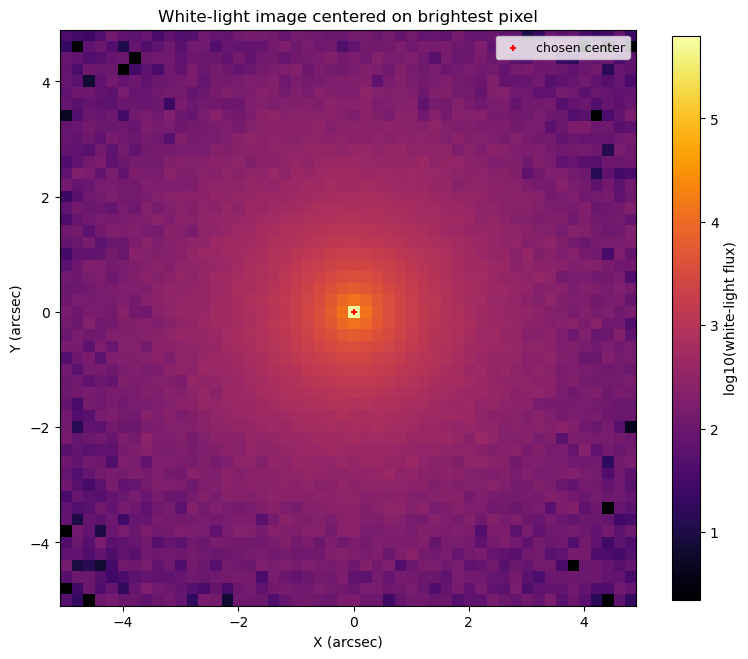

In [3]:
wl = white_light_image(cube)

# Find the brightest pixel in the white-light image
# np.unravel_index returns (y, x), so swap to store CENTER_PX as (x, y)
CENTER = np.unravel_index(np.nanargmax(wl), wl.shape)[::-1]

# CENTER is the center in arcsec, still stored as (x, y)
CENTER_ARC = (CENTER[0] * cube.pixel_scale,
              CENTER[1] * cube.pixel_scale)

plt.figure(figsize=(8, 7))
m = plt.imshow(
    np.log10(np.maximum(wl, wl[wl > 0].min())),
    # center the axes on the chosen center, and make sure the axes are in arcsec
    extent=(
        -CENTER_ARC[0] - 0.5 * cube.pixel_scale,
        cube.shape[1] * cube.pixel_scale - CENTER_ARC[0] - 0.5 * cube.pixel_scale,
        -CENTER_ARC[1] - 0.5 * cube.pixel_scale,
        cube.shape[0] * cube.pixel_scale - CENTER_ARC[1] - 0.5 * cube.pixel_scale),
    origin="lower",
    cmap="inferno")
plt.scatter(0, 0, marker="+", color="red", s=20, label="chosen center")
plt.xlabel("X (arcsec)")
plt.ylabel("Y (arcsec)")

plt.colorbar(mappable=m, label="log10(white-light flux)", shrink=0.87)
plt.legend(fontsize=9)
plt.title("White-light image centered on brightest pixel")
plt.tight_layout()
plt.show()

## 4. Spatial binning: radial annuli only

Template calibration works annulus by annulus: stellar-population mixture
is expected to vary smoothly with galactocentric radius, not sharply with
azimuthal angle at fixed radius, so each radial bin is fit once (summing
over every spaxel in that annulus, at every angle) to find the templates
that annulus actually needs. This is deliberately **radial-only, no
angular sectoring** -- unlike `07_full_galaxy_analysis.ipynb`'s own
kinematic bins, which *do* need angular resolution (rotation shows up
directionally, template content doesn't).

`REFERENCE_R_EDGES_ARCSEC` below is the **same radial reference set**
`07_full_galaxy_analysis.ipynb` rescales from, so the annulus this
notebook conditions a template subset for lines up with the radial
extent of that notebook's own real kinematic bins -- just without
splitting each annulus further by angle.

`plot_bin_map` (defined below) is the same function
`07_full_galaxy_analysis.ipynb` uses for its own maps -- reused unchanged
so this notebook's bin map reads in the identical style, except there is
only ever one wedge per radius here (no angular grid lines drawn, since
there's only one angular bin per annulus).

9 populated radial bins out to r=4.50" (requested RMAX_ARCSEC=29.66")


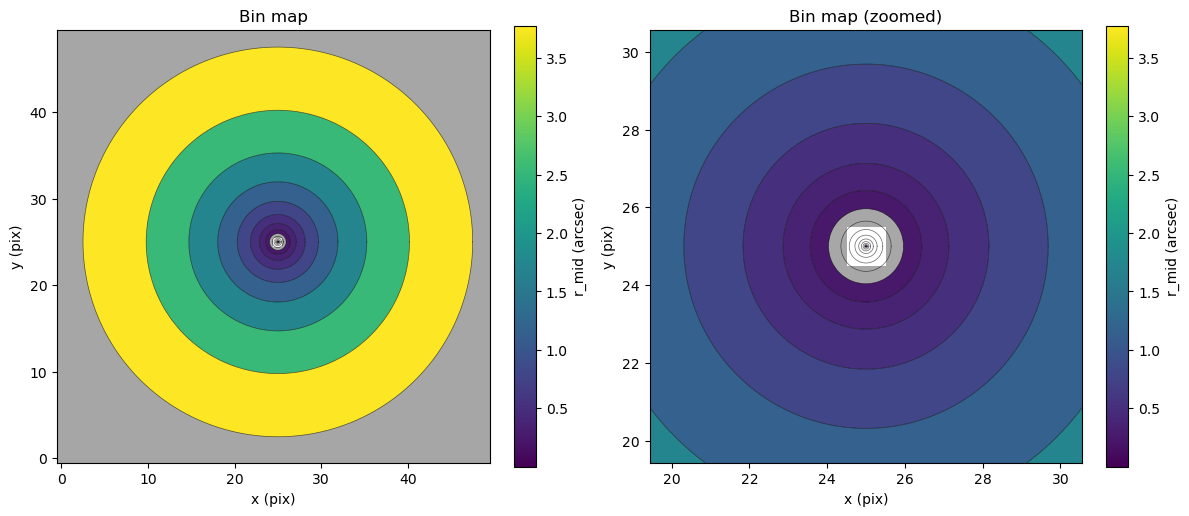

In [4]:
REFERENCE_R_EDGES_ARCSEC = np.array([
    0.021, 0.048, 0.088, 0.147, 0.235, 0.365, 0.557, 0.841, 1.261, 1.883,
    2.801, 4.160, 6.171, 9.143, 13.540, 20.044, 29.662, 43.888,
])  # same reference radial edges 07_full_galaxy_analysis.ipynb rescales from

RMAX_ARCSEC = REFERENCE_R_EDGES_ARCSEC[-2]  # <-- the parameter to change; radial coverage in arcsec

ny, nx = cube.shape[0], cube.shape[1]
fov_half_extent = 0.5 * min(nx, ny) * cube.pixel_scale
r_edges_full = REFERENCE_R_EDGES_ARCSEC * (0.9 * fov_half_extent / REFERENCE_R_EDGES_ARCSEC[-1])
# snap DOWN to the nearest real (rescaled) reference edge <= RMAX_ARCSEC, rather than appending
# RMAX_ARCSEC itself as a brand-new edge -- avoids a thin sliver ring at the outer boundary.
r_edges = r_edges_full[r_edges_full <= RMAX_ARCSEC]
if len(r_edges) < 2:
    r_edges = r_edges_full[:2]

theta_edges = uniform_theta_edges(1)  # radial-only: one angular bin (the full circle) per annulus
bins = DartboardBins(r_edges=r_edges, theta_edges=theta_edges, center=CENTER)
bin_id_map, bin_table = assign_spaxels_to_bins(cube.shape, bins, pixel_scale=cube.pixel_scale)
print(f"{len(bin_table)} populated radial bins out to r={r_edges[-1]:.2f}\" "
      f"(requested RMAX_ARCSEC={RMAX_ARCSEC:.2f}\")")


def plot_bin_map(ax, bin_table, bins, values_by_bin_id, center_pix, pa_deg, pixel_scale,
                  background=None, cmap="viridis", vmin=None, vmax=None,
                  grid_color="black", grid_lw=0.5, grid_alpha=0.6, colorbar_label=None,
                  add_cbar=True):
    """Paints each populated bin as a filled wedge at its real sky
    position/extent, with explicit grid-line boundaries drawn on top --
    the same function `07_full_galaxy_analysis.ipynb` uses for its real
    kinematic maps, reused here unchanged so this notebook's bin map
    reads identically to that capstone notebook's own. Angular grid
    spokes are only drawn when there's more than one angular bin
    (`bins.n_angular > 1`) -- a single full-circle bin per annulus (this
    notebook's own scheme) has no meaningful angular boundary to draw.
    """
    bx, by = center_pix
    if background is not None:
        ax.imshow(background, origin="lower", cmap="gray", alpha=0.35, zorder=0)

    vals_present = np.array([v for v in values_by_bin_id.values() if np.isfinite(v)])
    if vmin is None:
        vmin = -np.nanmax(np.abs(vals_present)) if cmap == "RdBu_r" else np.nanmin(vals_present)
    if vmax is None:
        vmax = np.nanmax(np.abs(vals_present)) if cmap == "RdBu_r" else np.nanmax(vals_present)
    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    cmap_obj = plt.get_cmap(cmap)
    cmap_obj.set_bad("grey")

    for row in bin_table:
        bid = row["bin_id"]
        if bid not in values_by_bin_id:
            continue
        color = cmap_obj(norm(values_by_bin_id[bid]))
        if row["theta_mid"] is None:
            # collapsed center bin -- a full circle out to the first radial edge
            r_hi = bins.r_edges[1] / pixel_scale
            wedge = mpatches.Wedge((bx, by), r_hi, 0.0, 360.0, facecolor=color,
                                    edgecolor="none", zorder=1)
        else:
            r_lo = bins.r_edges[row["r_index"]] / pixel_scale
            r_hi = bins.r_edges[row["r_index"] + 1] / pixel_scale
            theta_lo = np.degrees(bins.theta_edges[row["theta_index"]]) + pa_deg
            theta_hi = np.degrees(bins.theta_edges[row["theta_index"] + 1]) + pa_deg
            wedge = mpatches.Wedge((bx, by), r_hi, theta_lo, theta_hi, width=r_hi - r_lo,
                                    facecolor=color, edgecolor="none", zorder=1)
        ax.add_patch(wedge)

    t = np.linspace(0.0, 2 * np.pi, 400)
    for r_edge in bins.r_edges[1:]:
        rp = r_edge / pixel_scale
        ax.plot(bx + rp * np.cos(t), by + rp * np.sin(t), color=grid_color,
                lw=grid_lw, alpha=grid_alpha, zorder=2)
    if bins.n_angular > 1:
        r_inner_pix = bins.r_edges[1] / pixel_scale
        r_max_pix = bins.r_edges[-1] / pixel_scale
        for theta_edge in bins.theta_edges:
            th = theta_edge + np.radians(pa_deg)
            ax.plot([bx + r_inner_pix * np.cos(th), bx + r_max_pix * np.cos(th)],
                    [by + r_inner_pix * np.sin(th), by + r_max_pix * np.sin(th)],
                    color=grid_color, lw=grid_lw, alpha=grid_alpha, zorder=2)

    if add_cbar:
        sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap_obj)
        sm.set_array([])
        cbar = plt.colorbar(sm, ax=ax, fraction=0.046)
        if colorbar_label:
            cbar.set_label(colorbar_label)
    ax.set_aspect("equal")


# No kinematics exist yet at this stage -- color each bin by its own radial midpoint,
# a placeholder that still shows the bin geometry clearly.
r_mid_by_bin = {row["bin_id"]: row["r_mid"] for row in bin_table}

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
plot_bin_map(axes[0], bin_table, bins, r_mid_by_bin, center_pix=CENTER, pa_deg=0.0,
             pixel_scale=cube.pixel_scale, background=wl, cmap="viridis",
             colorbar_label="r_mid (arcsec)")
axes[0].set_title("Bin map"); axes[0].set_xlabel("x (pix)"); axes[0].set_ylabel("y (pix)")

plot_bin_map(axes[1], bin_table, bins, r_mid_by_bin, center_pix=CENTER, pa_deg=0.0,
             pixel_scale=cube.pixel_scale, background=wl, cmap="viridis",
             colorbar_label="r_mid (arcsec)")
zoom_pix = (2.0 * REFERENCE_R_EDGES_ARCSEC[6]) / cube.pixel_scale  # a few arcsec, regardless of target size
axes[1].set_xlim(CENTER[0] - zoom_pix, CENTER[0] + zoom_pix)
axes[1].set_ylim(CENTER[1] - zoom_pix, CENTER[1] + zoom_pix)
axes[1].set_title("Bin map (zoomed)"); axes[1].set_xlabel("x (pix)"); axes[1].set_ylabel("y (pix)")
plt.tight_layout(); plt.show()


## 5. Extract per-bin spectra

In [5]:
bin_specs = []
for row in bin_table:
    mask = bin_id_map == row["bin_id"]
    wave_obs, flux_obs, error_obs = extract_aperture_spectrum(cube, mask)
    wave_rest = wave_obs / (1.0 + Z)
    in_window = (wave_rest >= WAVEFITMIN) & (wave_rest <= WAVEFITMAX)
    wave_w, flux_w, error_w = wave_rest[in_window], flux_obs[in_window], error_obs[in_window]
    wave_fit, flux_fit = mask_wavelength_windows(wave_w, flux_w, windows=SKY_RESIDUAL_WINDOWS)
    _, errors = mask_wavelength_windows(wave_w, error_w, windows=SKY_RESIDUAL_WINDOWS)

    bin_specs.append((wave_fit, flux_fit, errors))
    row["snr"] = float(np.median(flux_fit) / np.median(errors))

print(f"{'bin_id':>6}  {'r_mid (\"))':>10}  {'n_spaxels':>9}  {'S/N':>7}")
for row in bin_table:
    print(f"{row['bin_id']:>6}  {row['r_mid']:>10.2f}  {row['n_spaxels']:>9d}  {row['snr']:>7.1f}")


bin_id  r_mid ("))  n_spaxels      S/N
     0        0.00          1    998.6
     9        0.24          8     48.7
    10        0.36          4     19.2
    11        0.53         24     32.8
    12        0.79         32     22.3
    13        1.16         76     20.6
    14        1.72        188     17.4
    15        2.55        392     12.5
    16        3.77        872      8.9


## 6. Load the full E-MILES grid

Same grid every other notebook in this series uses
(`kinextract.emiles`) -- `select=None` (the default) returns every
packed template.


In [6]:
templates, template_wave, names, ages, metals = load_emiles_templates(EMILES_GRID)
print(f"loaded the full E-MILES grid: {len(templates)} templates "
      f"({len(set(ages.tolist()))} ages x {len(set(metals.tolist()))} metallicities)")

loaded the full E-MILES grid: 636 templates (53 ages x 12 metallicities)


## 7. Fit every bin against the full grid, and threshold

Same `fit_losvd` call as every other notebook in this series -- the
template stack is just wider (636 templates instead of a hand-picked
handful). `NNLS_THRESHOLD` matches this package's own established
convention for "selected" (a normalized-weight floor, not a statistical
significance test -- see `template_reduction.py`'s own docstring).

**`penalty_order=2` pinned deliberately, alongside the fixed `lam=2.0`
this section already used.** This notebook's job is fast, repeated
NNLS-based template selection across many bins and iterations, not
per-fit shape-residual accuracy -- so it deliberately keeps a cheap,
fixed `lam` rather than adaptive selection: `penalty_order=3` (the
current package default) is calibrated for adaptive selection, and a
fixed `lam=2.0` under it is essentially unregularized, which changes NNLS
weight recovery enough to break the "decoys drop out" behavior this
section and Section 8 depend on.

**Robust-scaled cleaning (`fit_losvd_clean`, `robust_scale=True`), not
plain `fit_losvd`.** Real contamination (sky residuals, bad pixels) has
roughly *fixed absolute amplitude* across the field, while the galaxy's
own signal falls off steeply with radius -- so a fixed contamination
source becomes a *growing fraction* of the (shrinking) signal outward, and
`chi2_red` can inflate by orders of magnitude with radius on a real
target if nothing clips it out (`07_full_galaxy_analysis.ipynb`'s own
Section 4 documents the same mechanism at kinematic-fitting scale, and is
where the `robust_scale=True` reasoning is spelled out in full). Every
bin's own surviving (non-clipped) pixel set is written back into
`bin_specs` below, so Section 8's iterative reduction -- which still
calls plain `fit_losvd` internally -- fits the *cleaned* data throughout,
not the original contaminated set.

**This fit also gives a cheap, reusable rough `(V, sigma)` estimate per
radius**, collected below alongside `chi2_red`/`n_selected`.
`07_full_galaxy_analysis.ipynb` uses this radial profile to center each
of its own (far more numerous, angularly-subdivided) bins' velocity grids
directly, instead of repeating an independent wide-pass fit per bin --
checked directly against a real run: `V` varies by at most ~30 km/s
across angle at fixed radius, `sigma` by ~5-16 km/s, both tiny next to
the `NSIG*sigma` margin that grid already carries, so a per-radius
estimate is a safe stand-in for a per-bin one here.

In [7]:
NNLS_THRESHOLD = 1e-3
CLIP_SIGMA = 3.0        # fit_losvd_clean's clip threshold, in robust-scaled units -- see Section 7 markdown
MAX_CLEAN_ITER = 3
cfg = FitConfig(vmin=-400.0, vmax=400.0, lam_selection="fixed", lam=2.0, penalty_order=2)
v_grid = cfg.build_velocity_grid()

full_grid_results = []
for i, ((wave_fit, flux_fit, errors), row) in enumerate(zip(bin_specs, bin_table)):
    A_stack = build_template_stack(wave_fit, template_wave, templates, v_grid)
    A_stack_w = A_stack / errors[None, :, None]
    y_w = flux_fit / errors

    t0 = time.time()
    result = fit_losvd_clean(A_stack_w, y_w, cfg, clip_sigma=CLIP_SIGMA,
                              max_iter=MAX_CLEAN_ITER, robust_scale=True)
    dt = time.time() - t0

    # write the surviving (non-clipped) pixel set back into bin_specs -- Section 8's
    # iterative reduction (and this notebook's own saved radial kinematics) then fit
    # against the same cleaned data throughout, not the original contaminated one.
    keep = ~result["clipped_mask"]
    bin_specs[i] = (wave_fit[keep], flux_fit[keep], errors[keep])

    w_norm = result["w"] / result["w"].sum()
    selected = np.where(w_norm > NNLS_THRESHOLD)[0]
    A_eff_w = np.tensordot(result["w"], A_stack_w, axes=([0], [0]))
    chi2_red = float(np.sum(((A_eff_w @ result["b"] - y_w)[keep]) ** 2)) / int(keep.sum())
    moments = compute_losvd_moments(v_grid, result["b"], fit_h3h4=False)

    full_grid_results.append(dict(bin_id=row["bin_id"], r_mid=row["r_mid"], chi2_red=chi2_red,
                                   n_selected=len(selected), fit_time=dt, n_clipped=result["n_clipped"],
                                   vherm=moments["vherm"], sherm=moments["sherm"]))
    print(f"bin {row['bin_id']:2d}  r={row['r_mid']:5.2f}\"  fit_time={dt:.1f}s  "
          f"chi2_red={chi2_red:.2f}  n_selected={len(selected)}/{len(templates)}  "
          f"n_clipped={result['n_clipped']}/{len(wave_fit)}  "
          f"V={moments['vherm']:+.1f}  sigma={moments['sherm']:.1f}")


bin  0  r= 0.00"  fit_time=6.8s  chi2_red=0.87  n_selected=15/636  n_clipped=2/306  V=+21.3  sigma=79.9


bin  9  r= 0.24"  fit_time=2.6s  chi2_red=0.92  n_selected=6/636  n_clipped=2/306  V=+25.6  sigma=85.0


bin 10  r= 0.36"  fit_time=2.3s  chi2_red=0.97  n_selected=7/636  n_clipped=1/306  V=+10.9  sigma=102.5


bin 11  r= 0.53"  fit_time=1.3s  chi2_red=1.01  n_selected=3/636  n_clipped=0/306  V=+14.7  sigma=93.9


bin 12  r= 0.79"  fit_time=4.7s  chi2_red=0.79  n_selected=4/636  n_clipped=3/306  V=+17.9  sigma=77.0


bin 13  r= 1.16"  fit_time=1.4s  chi2_red=0.97  n_selected=4/636  n_clipped=0/306  V=+29.0  sigma=86.5


bin 14  r= 1.72"  fit_time=1.6s  chi2_red=1.03  n_selected=4/636  n_clipped=0/306  V=+39.1  sigma=108.6


bin 15  r= 2.55"  fit_time=4.4s  chi2_red=0.91  n_selected=4/636  n_clipped=4/306  V=+25.3  sigma=96.6


bin 16  r= 3.77"  fit_time=1.0s  chi2_red=0.96  n_selected=1/636  n_clipped=0/306  V=-11.0  sigma=101.9


## 8. Iterative template-set reduction

Refit with only the surviving templates, re-threshold, repeat until the
*union* of surviving templates across bins stabilizes (or
`MAX_ITERATIONS` is hit) -- see `template_reduction.py`'s own module
docstring for why the union, not each bin's own set, is what has to
stabilize, and why this loop can only shrink or hold steady from one
iteration to the next.

**Expensive by construction** (every iteration refits every participating
bin against however many templates survived so far) -- `RUN_ITERATIVE_
REDUCTION` gates whether to do this at all, and `BINS_SUBSET` lets it run
on a representative subset of bins instead of every one (e.g. one angular
sector's worth of radial bins, for a target where azimuthal symmetry is
a reasonable assumption) rather than the full bin set.


took 23.7s
converged=True  n_iterations=2
union_selected: 40 / 636 templates


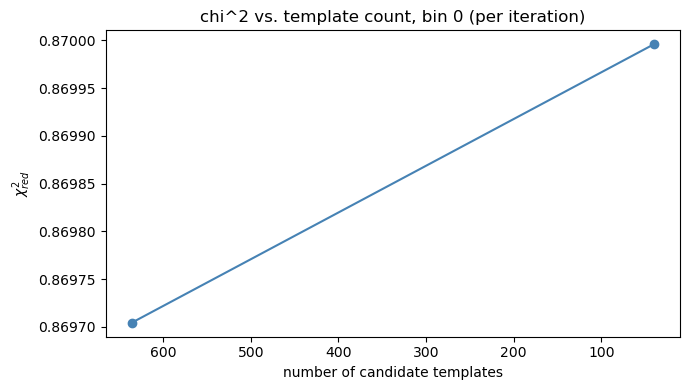

In [8]:
RUN_ITERATIVE_REDUCTION = True
MAX_ITERATIONS = 10
BINS_SUBSET = None  # None = every bin; or e.g. a list of bin indices for a representative subset

if RUN_ITERATIVE_REDUCTION:
    t0 = time.time()
    reduction_result = reduce_templates_iteratively(
        bin_specs, templates, template_wave, cfg,
        threshold=NNLS_THRESHOLD, max_iterations=MAX_ITERATIONS, bins_subset=BINS_SUBSET,
    )
    print(f"took {time.time()-t0:.1f}s")
    print(f"converged={reduction_result.converged}  n_iterations={reduction_result.n_iterations}")
    print(f"union_selected: {len(reduction_result.union_selected)} / {len(templates)} templates")

    # chi^2 vs. number of templates retained, per iteration, for one representative bin --
    # this is the plateau check: does fit quality actually stop improving once enough
    # templates are retained, or does it keep improving indefinitely (which would suggest
    # more templates are needed, or that the threshold is too aggressive)?
    example_bin = (BINS_SUBSET[0] if BINS_SUBSET else 0)
    history = reduction_result.per_bin_history[example_bin]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot([h["n_templates"] for h in history], [h["chi2_red"] for h in history], "o-", color="steelblue")
    ax.set_xlabel("number of candidate templates"); ax.set_ylabel(r"$\chi^2_{red}$")
    ax.set_title(f"chi^2 vs. template count, bin {example_bin} (per iteration)")
    ax.invert_xaxis()
    plt.tight_layout(); plt.show()


## 9. Synthetic mode only: check against known truth

Only meaningful when `DATA_MODE == "synthetic"` -- there is no ground
truth for real data. This is the direct answer to the methodological
question Section 8 exists to ask: did the reduction converge to a
sensible, non-trivial subset (not collapsed to a single template), and
does it recover something close to the actual injected templates (allowing
for real template-mixture degeneracy substituting a near-identical
neighbor for one of them)?


In [9]:
if DATA_MODE == "synthetic" and RUN_ITERATIVE_REDUCTION:
    true_select = cube.truth["template_select"]
    true_indices = [i for i, (a, z) in enumerate(zip(ages, metals))
                    if any(abs(a - ta) < 1e-2 and abs(z - tz) < 1e-2 for ta, tz in true_select)]

    print(f"true injected templates: {true_select}")
    print(f"recovered union ({len(reduction_result.union_selected)} templates):")
    for i in reduction_result.union_selected:
        flag = "  <-- true" if i in true_indices else ""
        print(f"  age={ages[i]:.2f} Gyr  [M/H]={metals[i]:+.2f}{flag}")

    n_true_recovered = len(set(reduction_result.union_selected.tolist()) & set(true_indices))
    print(f"\n{n_true_recovered}/{len(true_indices)} true templates recovered exactly "
          f"(degenerate near-neighbors substituting for the rest is expected, not a failure -- "
          f"see this package's own template-mixture-degeneracy documentation, e.g. "
          f"`multi_template.py`'s module docstring)")
    assert len(reduction_result.union_selected) > 1, (
        "collapsed to a single template -- the exact failure mode this synthetic check exists to catch"
    )


true injected templates: [(1.0, -0.66), (5.0, 0.06), (10.0, 0.06)]
recovered union (40 templates):
  age=12.00 Gyr  [M/H]=-0.25
  age=0.03 Gyr  [M/H]=-0.35
  age=13.00 Gyr  [M/H]=-0.35
  age=0.03 Gyr  [M/H]=-0.66
  age=0.45 Gyr  [M/H]=-0.66
  age=1.25 Gyr  [M/H]=-0.66
  age=12.00 Gyr  [M/H]=-0.66
  age=0.25 Gyr  [M/H]=-0.96
  age=0.60 Gyr  [M/H]=-0.96
  age=1.00 Gyr  [M/H]=-1.26
  age=1.00 Gyr  [M/H]=-1.49
  age=0.10 Gyr  [M/H]=-2.27
  age=0.80 Gyr  [M/H]=-2.27
  age=0.90 Gyr  [M/H]=-2.27
  age=0.04 Gyr  [M/H]=+0.06
  age=2.75 Gyr  [M/H]=+0.06
  age=3.50 Gyr  [M/H]=+0.06
  age=6.00 Gyr  [M/H]=+0.06
  age=7.00 Gyr  [M/H]=+0.06
  age=7.50 Gyr  [M/H]=+0.06
  age=11.00 Gyr  [M/H]=+0.06
  age=11.50 Gyr  [M/H]=+0.06
  age=14.00 Gyr  [M/H]=+0.06
  age=1.75 Gyr  [M/H]=+0.15
  age=4.50 Gyr  [M/H]=+0.15
  age=6.50 Gyr  [M/H]=+0.15
  age=0.60 Gyr  [M/H]=+0.26
  age=1.50 Gyr  [M/H]=+0.26
  age=3.00 Gyr  [M/H]=+0.26
  age=6.50 Gyr  [M/H]=+0.26
  age=14.00 Gyr  [M/H]=+0.26
  age=0.03 Gyr  [M/H]=+0.4

## 10. Save the template subset (and a rough radial `(V, sigma)` profile)

For `07_full_galaxy_analysis.ipynb` (or any future analysis of this same
target) to load instead of a hand-picked template list, and instead of
repeating Section 7's own per-bin fit as a per-bin wide-pass.

In [10]:
if RUN_ITERATIVE_REDUCTION:
    if DATA_MODE == "download":
        # A real target -- save under examples/data/muse/ so 05_noise_correlation.ipynb
        # and 07_full_galaxy_analysis.ipynb find it at the path they actually read.
        OUTPUT_PATH = f"../data/muse/{target_identifier.lower()}_template_subset.npz"
        RADIAL_KINEMATICS_PATH = f"../data/muse/{target_identifier.lower()}_radial_kinematics.npz"
    else:
        OUTPUT_PATH = f"../data/template_subset_{DATA_MODE}.npz"
        RADIAL_KINEMATICS_PATH = f"../data/radial_kinematics_{DATA_MODE}.npz"
    save_template_subset(reduction_result, bin_table, names, ages, metals, OUTPUT_PATH)
    print(f"saved template subset to {OUTPUT_PATH}")

    r_mid_arr = np.array([r["r_mid"] for r in full_grid_results])
    vherm_arr = np.array([r["vherm"] for r in full_grid_results])
    sherm_arr = np.array([r["sherm"] for r in full_grid_results])
    np.savez(RADIAL_KINEMATICS_PATH, r_mid=r_mid_arr, vherm=vherm_arr, sherm=sherm_arr)
    print(f"saved radial (V, sigma) profile to {RADIAL_KINEMATICS_PATH}")

saved template subset to ../data/template_subset_synthetic.npz
saved radial (V, sigma) profile to ../data/radial_kinematics_synthetic.npz


## Conclusion

**What this notebook did.** Fit every radial annulus against the full
636-template E-MILES grid (with robust-scaled cleaning, Section 7),
iteratively kept only the templates whose NNLS weight actually survives
somewhere, and saved the resulting union -- a much smaller, data-driven
template subset for the kinematic-fitting notebooks to load, instead of
a hand-picked recipe or the full grid.

**Key takeaways:**

- The reduced subset is a real reduction (a small fraction of the full
  grid) while still covering the range of stellar populations this target
  actually needs, at every radius that participated.
- Section 9's synthetic check confirms the reduction converges to a
  sensible, non-trivial subset rather than collapsing to a single
  template -- the specific failure mode this check exists to catch.
- **Every radial bin has to actually participate in the reduction for
  its own population to end up in the union.** A bin excluded from the
  fit (e.g. via `BINS_SUBSET`, for speed) contributes nothing to what
  gets kept, even if its own true population is completely different
  from every other bin's -- run every bin at least once for a target
  where population content might vary sharply with radius (the nucleus
  in particular).
- **Cleaning matters here too, not just at kinematic-fitting scale.**
  Section 7 uses `fit_losvd_clean` (robust-scaled), not plain `fit_losvd`
  -- real contamination has roughly fixed absolute amplitude while the
  galaxy signal falls off with radius, so an uncleaned `chi2_red` can
  inflate by orders of magnitude outward and corrupt which templates NNLS
  ends up favoring. Every downstream fit in this notebook (Section 8's
  reduction, the saved radial `(V, sigma)` profile) uses each bin's own
  cleaned pixel set.
- `chi2_red` is a hint, not the only check -- Section 8's plateau plot is
  the more direct answer to "do I have enough templates yet."

**Next**: `05_noise_correlation.ipynb` and `07_full_galaxy_analysis.ipynb`
both load this notebook's saved subset directly rather than re-deriving
it -- conditioning is a per-target, do-it-once step. `06_other_instruments.ipynb`
covers a case (HST/STIS long-slit spectroscopy) this notebook's own
radial-binning scheme doesn't generalize to yet, and still relies on a
hand-picked template list for that reason.

See `kinextract.binning`'s module docstring for the binning scheme,
`kinextract.mock_cube`'s for the synthetic-cube design, and
`kinextract.template_reduction`'s for the iterative-reduction
algorithm and convergence criterion.

## Forward-looking: other instruments

This whole pipeline -- cube download, spatial binning, full-grid
template reduction -- is built around a 2-D IFU geometry (MUSE's own
`(x, y, wavelength)` cube). Generalizing it to a fundamentally different
geometry, especially **HST/STIS long-slit spectroscopy** (a 1-D slit, not
a 2-D field), is real future work, not attempted here: the radial binning
scheme used here has no 1-D analog as written (a slit's own spatial axis
isn't a radius from a center), so that piece would need a genuinely
different binning scheme (e.g. simple bins along the slit), not just a
reused one. `06_other_instruments.ipynb` still uses a hand-picked
template list for exactly this reason.